# 作业2：运力调度（完成版）

保留教师 Notebook 的动态环境、TBG、BB、NSGA-II 四部分。原件不变；生产实现集中在 `task2/src/online.py`，这里逐段导入、运行与核验，避免 Notebook 与脚本维护两套算法。TODO1—5、finalize 和 Assignment 生成均有实际实现与反例。

课件场景是 10×10 km、20 min、20 对象、1 km/min；原 Notebook 的100对象、1000空间单位/2000时间单位另立示例。签到是代理需求，不是真实网约车单。

In [1]:
from pathlib import Path
import sys, os, json
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['OMP_NUM_THREADS']='1'
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'task2/src/online.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
if str(ROOT/'task2/src') not in sys.path:sys.path.insert(0,str(ROOT/'task2/src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from task2.scripts.build_figures import P, COLORS
from matplotlib.colors import LinearSegmentedColormap
VALUE_CMAP=LinearSegmentedColormap.from_list('p2value',[P['Paper'],P['P1'],P['C1'],P['Ink']])
get_ipython().run_line_magic('matplotlib','inline')
np.set_printoptions(precision=4,suppress=True)

## 1. 双边在线事件与两种离线目标

每个司机/订单只匹配一次；同刻先请求后司机（各按ID），同刻到达全部处理完再开批次。延迟=等待+距离/速度。离线分别求最小总延迟与最小最大延迟；它们是两个不同问题。

In [2]:
from task2.src.online import (Worker,Request,Assignment,SimulationEnvironment,TBGAlgorithm,BBAlgorithm,
    run_simulation,offline_reference,summarize,instance_ratios,bottleneck_assignment)
from scipy.optimize import linear_sum_assignment
C=np.array([[0.,6.],[6.,10.]])
i,j=linear_sum_assignment(C);bi,bj=bottleneck_assignment(C)
assert C[i,j].sum()==10 and C[i,j].max()==10
assert C[bi,bj].max()==6
print('sum-optimum max=10; bottleneck-optimum max=6（精确反例）')
sim=SimulationEnvironment(123)
sim.generate_synthetic_data(20,20,(0,20),(0,10))
opt_sum=offline_reference(sim.workers,sim.requests,objective='sum')
opt_max=offline_reference(sim.workers,sim.requests,objective='max')

sum-optimum max=10; bottleneck-optimum max=6（精确反例）


## 2. TBG：完成原 Cell4 的TODO1—5与finalize

请求到达时取 travel≤gamma 的最近司机；司机到达优先最早超阈值请求，否则取总延迟<gamma的最小者。gamma的单位是时间，距离要除以速度。finalize只使用真实剩余司机，不能制造供给。小gamma不会保证更低最大延迟。

In [3]:
rows=[]
for gamma in [.5,1,2,5,10,15]:
    method=TBGAlgorithm(gamma,speed=1)
    a=run_simulation(sim.workers,sim.requests,method,20)
    rows.append(dict(gamma=gamma,**summarize(a,20,20),**instance_ratios(a,opt_sum,opt_max)))
display(pd.DataFrame(rows).round(4))
assert len(run_simulation([],sim.requests,TBGAlgorithm(5),20))==0

,gamma,num_assigned,num_requests,num_workers,match_rate,unmatched_requests,avg_delay,max_delay,p95_delay,total_delay,avg_wait,avg_pickup_distance,ratio_sum,ratio_sum_status,ratio_max,ratio_max_status
0,0.5,20,20,20,1.0,0,8.0388,15.4285,13.2008,160.7761,3.7422,4.2967,1.7491,INSTANCE_RATIO,1.8429,INSTANCE_RATIO
1,1.0,20,20,20,1.0,0,8.0610,15.4285,13.2008,161.2192,3.8727,4.1883,1.7539,INSTANCE_RATIO,1.8429,INSTANCE_RATIO
2,2.0,20,20,20,1.0,0,7.1283,15.4285,13.2008,142.5651,3.2195,3.9087,1.5510,INSTANCE_RATIO,1.8429,INSTANCE_RATIO
3,5.0,20,20,20,1.0,0,5.8870,16.3938,13.2490,117.7397,2.4953,3.3917,1.2809,INSTANCE_RATIO,1.9582,INSTANCE_RATIO
4,10.0,20,20,20,1.0,0,6.6077,17.3097,16.6676,132.1541,2.4977,4.1100,1.4377,INSTANCE_RATIO,2.0676,INSTANCE_RATIO
5,15.0,20,20,20,1.0,0,6.1959,18.4508,13.2910,123.9185,2.0239,4.1720,1.3481,INSTANCE_RATIO,2.2039,INSTANCE_RATIO


## 3. BB：原 Cell8 的Assignment已给出，真正风险是丢弃队列

sum-KM是Notebook定义；课件的瓶颈版本另标BBmax。两者均保留未匹配对象再尝试。丢弃策略只作有明确身份的对照。下表同时给出覆盖率，部分匹配不计算与全服务离线最优的实例比值。

In [4]:
rows=[]
for theta in [.5,1,2,5]:
    for recycle,objective in [(True,'sum'),(True,'max'),(False,'sum')]:
        a=run_simulation(sim.workers,sim.requests,BBAlgorithm(theta,recycle=recycle,objective=objective),20)
        rows.append(dict(theta=theta,recycle=recycle,objective=objective,
            **summarize(a,20,20),**instance_ratios(a,opt_sum,opt_max)))
display(pd.DataFrame(rows).round(4))

,theta,recycle,objective,num_assigned,num_requests,num_workers,match_rate,unmatched_requests,avg_delay,max_delay,p95_delay,total_delay,avg_wait,avg_pickup_distance,ratio_sum,ratio_sum_status,ratio_max,ratio_max_status
0,0.5,True,sum,20,20,20,1.0,0,5.9043,17.6446,13.4760,118.0855,2.1829,3.7214,1.2847,INSTANCE_RATIO,2.1076,INSTANCE_RATIO
1,0.5,True,max,20,20,20,1.0,0,6.6943,17.6446,13.4427,133.8870,2.1829,4.5114,1.4566,INSTANCE_RATIO,2.1076,INSTANCE_RATIO
2,0.5,False,sum,4,20,20,0.2,16,5.2416,8.9144,8.3600,20.9663,0.1027,5.1389,NaN,INCOMPARABLE_CARDINALITY_OR_EMPTY,NaN,INCOMPARABLE_CARDINALITY_OR_EMPTY
3,1.0,True,sum,20,20,20,1.0,0,5.7862,17.4508,13.4663,115.7244,2.4079,3.3783,1.2590,INSTANCE_RATIO,2.0845,INSTANCE_RATIO
4,1.0,True,max,20,20,20,1.0,0,6.2415,17.4508,13.4330,124.8309,2.4079,3.8336,1.3581,INSTANCE_RATIO,2.0845,INSTANCE_RATIO
5,1.0,False,sum,6,20,20,0.3,14,4.6649,9.4144,9.1868,27.9897,0.5053,4.1597,NaN,INCOMPARABLE_CARDINALITY_OR_EMPTY,NaN,INCOMPARABLE_CARDINALITY_OR_EMPTY
6,2.0,True,sum,20,20,20,1.0,0,6.3291,20.7445,14.9838,126.5814,3.1079,3.2212,1.3771,INSTANCE_RATIO,2.4779,INSTANCE_RATIO
7,2.0,True,max,20,20,20,1.0,0,6.9685,20.3934,14.6064,139.3709,3.1079,3.8606,1.5162,INSTANCE_RATIO,2.4359,INSTANCE_RATIO
8,2.0,False,sum,8,20,20,0.4,12,4.3747,9.6013,9.2173,34.9973,1.0056,3.3690,NaN,INCOMPARABLE_CARDINALITY_OR_EMPTY,NaN,INCOMPARABLE_CARDINALITY_OR_EMPTY
9,5.0,True,sum,20,20,20,1.0,0,7.0969,19.0090,16.8340,141.9384,4.4579,2.6390,1.5442,INSTANCE_RATIO,2.2706,INSTANCE_RATIO


### Notebook原尺度的theta=50/100/200

这里速度=1空间单位/时间单位，绝不把数值1000直接称作km。该场景独立于上一课件场景。

In [5]:
nb_sim=SimulationEnvironment(123)
nb_sim.generate_synthetic_data(100,100,(0,2000),(0,1000))
rows=[]
for theta in [50,100,200]:
    a=run_simulation(nb_sim.workers,nb_sim.requests,BBAlgorithm(theta),2000)
    rows.append(dict(theta=theta,**summarize(a,100,100)))
display(pd.DataFrame(rows).round(4))

,theta,num_assigned,num_requests,num_workers,match_rate,unmatched_requests,avg_delay,max_delay,p95_delay,total_delay,avg_wait,avg_pickup_distance
0,50,100,100,100,1.0,0,328.9382,963.0527,672.8354,32893.8221,34.1826,294.7556
1,100,100,100,100,1.0,0,316.0974,1054.4763,685.2973,31609.7351,53.6826,262.4147
2,200,100,100,100,1.0,0,339.4355,889.4754,735.1777,33943.5502,103.6826,235.7529


## 4. 基础NSGA-II：接驾距离与送客距离

独立合成20司机/20个OD，10×10km，收入目标=欧氏送客km。没有套用进阶的5+2d车费。五seed、种群100、300代。静态多目标前沿需先给标量偏好，才有同目标的精确比较；这里是实例近似比，不是在线理论竞争保证。

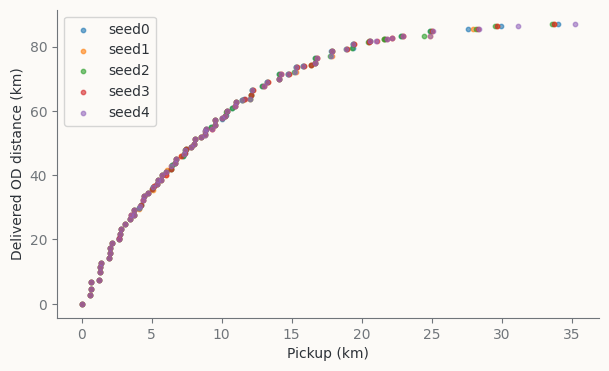

,seed,lam,optimal_utility,obtained_utility,instance_ratio
0,0,0.00,87.09670,87.09670,1.00000
1,1,0.00,87.09670,87.09670,1.00000
2,2,0.00,87.09670,87.09670,1.00000
3,3,0.00,87.09670,87.09670,1.00000
4,4,0.00,87.09670,87.09670,1.00000
5,0,0.25,79.00987,78.81512,1.00247
6,1,0.25,79.00987,78.88160,1.00163
7,2,0.25,79.00987,78.91895,1.00115
8,3,0.25,79.00987,78.88160,1.00163
9,4,0.25,79.00987,78.50870,1.00638


In [6]:
from task2.src.evolution import DispatchProblem,run_nsga,weighted_km
rng=np.random.default_rng(2024)
drv,origin,dest=(rng.uniform(0,10,(20,2)) for _ in range(3))
pickup=np.linalg.norm(drv[:,None]-origin[None],axis=-1)
trip=np.linalg.norm(dest-origin,axis=1)
problem=DispatchProblem(dict(drv=drv,o_xy=origin,d_xy=dest,pickup=pickup,fare=trip),K=20,radius=np.sqrt(200))
basic_runs=[run_nsga(problem,pop_size=100,n_gen=300,seed=s) for s in range(5)]
fig,ax=plt.subplots(figsize=(7,4))
for s,r in enumerate(basic_runs):ax.scatter(r['F'][:,1],-r['F'][:,0],s=10,label=f'seed{s}',alpha=.6)
ax.set(xlabel='Pickup (km)',ylabel='Delivered OD distance (km)');ax.legend();plt.show()
rows=[]
for reference in weighted_km(problem,[0,.25,.5,1,2]):
    lam=reference['lam'];opt=-reference['F'][0]-lam*reference['F'][1]
    for s,r in enumerate(basic_runs):
        val=np.max(-r['F'][:,0]-lam*r['F'][:,1])
        rows.append(dict(seed=s,lam=lam,optimal_utility=opt,obtained_utility=val,
                         instance_ratio=opt/val if val>0 else np.nan))
display(pd.DataFrame(rows).round(5))

## 5. 真实签到代理的空间需求扩展

使用前段训练日期的签到热点和相邻签到OD起点。将来源相同小时的起点有放回采样成60min模拟流，司机到达为模拟随机数；没有把不同日期的签到拼成真实出租车运营日。当地时间口径中的12对UTC矛盾有单独稳健性记录。

In [7]:
from task2.src.dispatch_data import load_data
bundle=load_data()
display(pd.DataFrame(bundle.audit['split']).T)
rng=np.random.default_rng(10)
pool=bundle.trips_train_inner[bundle.trips_train_inner.minute//60==18]
od=pool.iloc[rng.choice(len(pool),20)]
hot=bundle.checkins_train_inner.iloc[rng.choice(len(bundle.checkins_train_inner),20)]
w=[Worker(i,(float(row.x),float(row.y)),float(rng.uniform(0,60))) for i,(_,row) in enumerate(hot.iterrows())]
r=[Request(i,(float(row.ox),float(row.oy)),float(row.minute-1080)) for i,(_,row) in enumerate(od.iterrows())]
display(pd.DataFrame([dict(method=name,**summarize(run_simulation(w,r,algo,60),20,20)) for name,algo in
    [('TBG5',TBGAlgorithm(5)),('BBsum2',BBAlgorithm(2)),('BBmax2',BBAlgorithm(2,objective='max'))]]).round(4))

,rows,dates,start,end
trips_train_inner,19617,139,2012-04-03,2012-10-18
trips_validation,1972,35,2012-10-19,2012-11-26
trips_train,21589,174,2012-04-03,2012-11-26
trips_test,3961,75,2012-11-27,2013-02-15


,method,num_assigned,num_requests,num_workers,match_rate,unmatched_requests,avg_delay,max_delay,p95_delay,total_delay,avg_wait,avg_pickup_distance
0,TBG5,20,20,20,1.0,0,7.0839,26.4542,24.5439,141.6784,2.893,4.1909
1,BBsum2,20,20,20,1.0,0,5.5151,24.7652,11.7876,110.3021,0.900,4.6151
2,BBmax2,20,20,20,1.0,0,5.2907,24.7652,11.7876,105.8147,0.900,4.3907


完整55个开发实例、独立合成确认、单因素阈值、4时段代理实验及逐匹配记录分别由`run_online.py`与`run_online_studies.py`生成；本Notebook所有表和图来自当前Kernel实际执行。正式大批次结果与报告通过`docs/REPRODUCIBILITY_GUIDE.md`定位。